# Milestone 2: Conditional generation, guidance and noise-schedule tuning


* Task-1: Integrate the text encoder with the diffusion model
* Task-2: Baseline conditional generation
* Task-3: Tune classifier-free guidance and the noise schedule
* Task-4: First set of generated images


## 0. Setup

In [ ]:
import os, sys
from google.colab import drive
drive.mount("/content/drive")

REPO_URL = "https://github.com/Aryan16d/IE7615-Generative-milestone.git"
REPO_DIR = "/content/IE7615-Generative-milestone"
if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull -q
else:
    !git clone -q {REPO_URL} {REPO_DIR}
%pip install -q -r {REPO_DIR}/requirements.txt
sys.path.insert(0, REPO_DIR)

Mounted at /content/drive


In [ ]:
import inspect, json, shutil, textwrap, time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from IPython.display import Image as IPImage, display
from transformers import CLIPModel, CLIPProcessor
from diffusers import (StableDiffusionPipeline, PNDMScheduler, DDIMScheduler, DDPMScheduler,
                       EulerDiscreteScheduler, EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler)

SEED = 39
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE, DTYPE = "cuda", torch.float16
H = W = 512
SD_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CLIP_ID = "openai/clip-vit-large-patch14"

DRIVE_ROOT  = Path("/content/drive/MyDrive/t2i")
PROC_DIR    = DRIVE_ROOT / "data" / "processed"
SWEEP_DIR   = DRIVE_ROOT / "m2_sweeps"
REPO_DIR    = Path(REPO_DIR)
RESULTS_DIR = REPO_DIR / "results"
SAMPLES_DIR = RESULTS_DIR / "samples" / "m2_tuning"
METRICS_DIR = RESULTS_DIR / "metrics"
PLOTS_DIR   = RESULTS_DIR / "plots"
LOG_CSV     = RESULTS_DIR / "logs" / "generation_log.csv"
for d in (SAMPLES_DIR, METRICS_DIR, PLOTS_DIR, SWEEP_DIR):
    d.mkdir(parents=True, exist_ok=True)

prompts = [l.strip() for l in open(REPO_DIR / "prompts" / "test_prompts.txt") if l.strip()]
print(f"{len(prompts)} test prompts | device {DEVICE} | torch {torch.__version__}")
for i, p in enumerate(prompts, 1):
    print(f"  {i}. {p}")

5 test prompts | device cuda | torch 2.14.1+cu130
  1. a red double-decker bus driving down a busy city street
  2. two cats sleeping on a blue couch next to a remote control
  3. a plate with a slice of pizza on the left and a fork on the right
  4. a man riding a surfboard on a large wave at sunset
  5. a bowl of oranges and bananas on a wooden kitchen table


## 0.1 Helper functions
Diffusion loop, samplers, CLIPScore, logging and image grids, used by every section below.

In [ ]:
SCHEDULERS = {
    "PNDM (SD default)": lambda c: PNDMScheduler.from_config(c),
    "DDIM":              lambda c: DDIMScheduler.from_config(c),
    "DDPM":              lambda c: DDPMScheduler.from_config(c),
    "Euler":             lambda c: EulerDiscreteScheduler.from_config(c),
    "Euler (Karras)":    lambda c: EulerDiscreteScheduler.from_config(c, use_karras_sigmas=True),
    "Euler a":           lambda c: EulerAncestralDiscreteScheduler.from_config(c),
    "DPM++ 2M":          lambda c: DPMSolverMultistepScheduler.from_config(c, algorithm_type="dpmsolver++"),
    "DPM++ 2M Karras":   lambda c: DPMSolverMultistepScheduler.from_config(c, algorithm_type="dpmsolver++",
                                                                          use_karras_sigmas=True),
}


@torch.no_grad()
def encode_text(texts):
    ids = tokenizer(texts, padding="max_length", max_length=77, truncation=True,
                    return_tensors="pt").input_ids.to(DEVICE)
    return text_encoder(input_ids=ids).last_hidden_state


@torch.no_grad()
def denoise(scheduler, cond, uncond, guidance, steps, seed):
    scheduler.set_timesteps(steps, device=DEVICE)
    shape = (1, unet.config.in_channels, H // 8, W // 8)
    noise = torch.randn(shape, generator=torch.Generator(DEVICE).manual_seed(seed), device=DEVICE, dtype=cond.dtype)
    latents = noise.repeat(len(cond), 1, 1, 1) * scheduler.init_noise_sigma

    do_cfg = guidance > 1
    emb = torch.cat([uncond, cond]) if do_cfg else cond
    kw = {}
    if "generator" in inspect.signature(scheduler.step).parameters:
        kw["generator"] = torch.Generator(DEVICE).manual_seed(seed)

    for t in scheduler.timesteps:
        x = torch.cat([latents] * 2) if do_cfg else latents
        eps = unet(scheduler.scale_model_input(x, t), t, encoder_hidden_states=emb).sample
        if do_cfg:
            eps_u, eps_c = eps.chunk(2)
            eps = eps_u + guidance * (eps_c - eps_u)
        latents = scheduler.step(eps, t, latents, **kw).prev_sample
    return latents


@torch.no_grad()
def decode(latents):
    img = vae.decode(latents / vae.config.scaling_factor).sample
    img = (img / 2 + 0.5).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()
    return [Image.fromarray((x * 255).round().astype("uint8")) for x in img]


def nsfw_flags(images):
    px = pipe.feature_extractor(images, return_tensors="pt").pixel_values.to(DEVICE, DTYPE)
    arr = np.stack([np.asarray(i, dtype=np.float32) / 255 for i in images])
    _, flags = pipe.safety_checker(images=arr, clip_input=px)
    return [bool(f) for f in flags]


def generate(cond, uncond, seed, scheduler, steps, guidance):
    sched = SCHEDULERS[scheduler](pipe.scheduler.config)
    torch.cuda.synchronize(); t0 = time.time()
    imgs = decode(denoise(sched, cond, uncond.expand(len(cond), -1, -1), guidance, steps, seed))
    torch.cuda.synchronize(); dt = (time.time() - t0) / len(cond)
    flags = nsfw_flags(imgs)
    imgs = [Image.new("RGB", im.size) if f else im for im, f in zip(imgs, flags)]
    return imgs, dt, flags


@torch.no_grad()
def clip_score(images, texts):
    images = [Image.open(i).convert("RGB") if isinstance(i, (str, Path)) else i for i in images]
    px = clip_proc(images=images, return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
    tok = clip_proc(text=list(texts), padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEVICE)
    img = clip_model.visual_projection(clip_model.vision_model(pixel_values=px).pooler_output)
    txt = clip_model.text_projection(clip_model.text_model(input_ids=tok["input_ids"],
                                                           attention_mask=tok["attention_mask"]).pooler_output)
    img = (img / img.norm(dim=-1, keepdim=True)).float()
    txt = (txt / txt.norm(dim=-1, keepdim=True)).float()
    return [round(float(x), 2) for x in (img * txt).sum(-1).clamp(min=0).cpu() * 100]


def mean_saturation(img):
    return round(float(np.asarray(img.convert("HSV"))[..., 1].mean() / 255), 4)


metrics = []
STAMP = datetime.now().strftime("%Y%m%d-%H%M%S")


def rel(path):
    return str(path.relative_to(REPO_DIR)) if path.is_relative_to(REPO_DIR) else str(path)


def record(images, texts, seed, out_dir, experiment, scheduler, steps, guidance, runtime_s, flags,
           ext="jpg", tag="", notes=""):
    out_dir.mkdir(parents=True, exist_ok=True)
    scores = [float("nan") if f else s for s, f in zip(clip_score(images, texts), flags)]
    log_rows = []
    for k, (img, text, score, flag) in enumerate(zip(images, texts, scores, flags), 1):
        pid = prompts.index(text) + 1 if text in prompts else k
        path = out_dir / f"{tag}p{pid:02d}_s{seed}.{ext}"
        img.save(path, quality=92)
        note = "; ".join(n for n in [notes, "safety checker flagged (black image)" if flag else ""] if n)
        log_rows.append(dict(run_id=f"m2-{STAMP}-{len(metrics) + 1:03d}",
                             timestamp=datetime.now().isoformat(timespec="seconds"), milestone="M2",
                             prompt=text, seed=seed, model_id=SD_ID, scheduler=scheduler, num_steps=steps,
                             guidance_scale=guidance, height=H, width=W, output_path=rel(path),
                             runtime_s=round(runtime_s, 2), notes=note))
        metrics.append(dict(experiment=experiment, prompt_id=pid, prompt=text, seed=seed, scheduler=scheduler,
                            steps=steps, guidance=guidance, clip_score=score,
                            saturation=float("nan") if flag else mean_saturation(img),
                            runtime_s=round(runtime_s, 2), flagged=flag, path=rel(path)))
    pd.DataFrame(log_rows).to_csv(LOG_CSV, mode="a", index=False, header=not LOG_CSV.exists())
    return scores


def save_grid(images, path, row_labels=None, col_labels=None, cell=3.0, title=None, wrap=28):
    R, C = len(images), max(len(r) for r in images)
    fig, ax = plt.subplots(R, C, figsize=(cell * C, cell * R + (0.4 if title else 0)), squeeze=False)
    for i in range(R):
        for j in range(C):
            a = ax[i, j]
            a.set_xticks([]); a.set_yticks([])
            for s in a.spines.values():
                s.set_visible(False)
            if j < len(images[i]):
                a.imshow(images[i][j])
            if i == 0 and col_labels:
                a.set_title(textwrap.fill(str(col_labels[j]), wrap), fontsize=9)
            if j == 0 and row_labels:
                a.set_ylabel(textwrap.fill(str(row_labels[i]), wrap), fontsize=8)
    if title:
        fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=70, pil_kwargs={"quality": 85}); plt.close(fig)
    return path


def show(path, width=1000):
    display(IPImage(filename=str(path), width=width))

## 1. Integrating the text encoder with the diffusion model
Stable Diffusion is a latent diffusion model. In M1 we called `pipe(prompt)`; here we connect the parts ourselves:

```
prompt ──tokenizer──► 77 token ids ──CLIP text encoder──► c ∈ R^{77×768}
                                                             │ (cross-attention)
z_T ~ N(0, I) ∈ R^{4×64×64} ──► UNet ε_θ(z_t, t, c) ──scheduler step──► z_{t-1} … ► z_0 ──VAE decoder──► 512×512 image
```

**Classifier-free guidance.** Each step runs the UNet with the prompt embedding `c` and the empty-prompt embedding `∅`:

  ε̂ = ε_θ(z_t, t, ∅) + w · (ε_θ(z_t, t, c) − ε_θ(z_t, t, ∅))

`w = 1` is plain conditional sampling; larger `w` follows the prompt more strongly.

In [ ]:
pipe = StableDiffusionPipeline.from_pretrained(SD_ID, dtype=DTYPE, variant="fp16").to(DEVICE)
pipe.set_progress_bar_config(disable=True)
tokenizer, text_encoder, unet, vae = pipe.tokenizer, pipe.text_encoder, pipe.unet, pipe.vae

clip_model = CLIPModel.from_pretrained(CLIP_ID, dtype=DTYPE).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)

n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"text encoder : {type(text_encoder).__name__:22s} {n_params(text_encoder):7.1f} M params | hidden {text_encoder.config.hidden_size}")
print(f"UNet         : {type(unet).__name__:22s} {n_params(unet):7.1f} M params | cross_attention_dim {unet.config.cross_attention_dim}")
print(f"VAE          : {type(vae).__name__:22s} {n_params(vae):7.1f} M params | latent channels {vae.config.latent_channels}, scale {vae.config.scaling_factor}")
print(f"scheduler    : {type(pipe.scheduler).__name__} | {pipe.scheduler.config.num_train_timesteps} train steps, beta schedule '{pipe.scheduler.config.beta_schedule}'")
assert unet.config.cross_attention_dim == text_encoder.config.hidden_size

text encoder : CLIPTextModel            123.1 M params | hidden 768
UNet         : UNet2DConditionModel     859.5 M params | cross_attention_dim 768
VAE          : AutoencoderKL             83.7 M params | latent channels 4, scale 0.18215
scheduler    : PNDMScheduler | 1000 train steps, beta schedule 'scaled_linear'


In [ ]:
cond = encode_text(prompts)
uncond = encode_text([""])
print("cond:", tuple(cond.shape), cond.dtype, "| uncond:", tuple(uncond.shape))

gap = (cond.float() - uncond.float()).norm(dim=-1).mean(-1).cpu()
for p, g in zip(prompts, gap):
    print(f"  ||c - ∅|| = {g:5.2f}   {p}")

cond: (5, 77, 768) torch.float16 | uncond: (1, 77, 768)
  ||c - ∅|| = 35.92   a red double-decker bus driving down a busy city street
  ||c - ∅|| = 36.20   two cats sleeping on a blue couch next to a remote control
  ||c - ∅|| = 34.80   a plate with a slice of pizza on the left and a fork on the right
  ||c - ∅|| = 36.42   a man riding a surfboard on a large wave at sunset
  ||c - ∅|| = 36.17   a bowl of oranges and bananas on a wooden kitchen table


### 1.1 Sanity check: our loop reproduces `pipe()`
Same prompt, seed 39, PNDM, 50 steps, `w = 7.5`. Small differences come from fp16 GPU kernels.

pixel diff vs pipe(): mean 0.628, max 86 (0–255 scale)


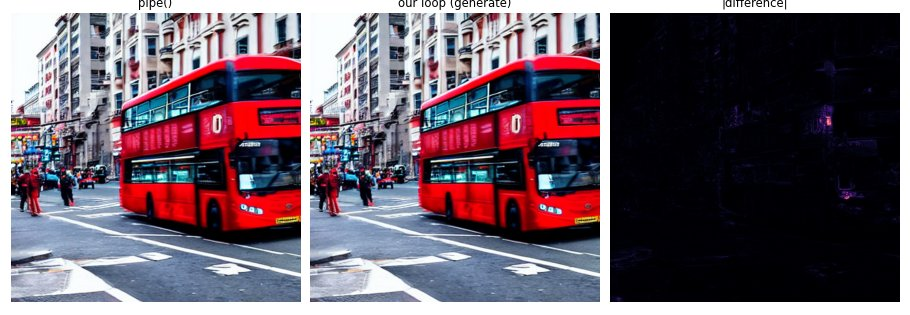

In [ ]:
ref = pipe(prompts[0], num_inference_steps=50, guidance_scale=7.5,
           generator=torch.Generator(DEVICE).manual_seed(SEED)).images[0]
ours = generate(cond[:1], uncond, SEED, "PNDM (SD default)", 50, 7.5)[0][0]

diff = np.abs(np.asarray(ref, dtype=np.int16) - np.asarray(ours, dtype=np.int16))
print(f"pixel diff vs pipe(): mean {diff.mean():.3f}, max {diff.max()} (0–255 scale)")
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for a, im, t in zip(ax, [ref, ours, diff.mean(-1)], ["pipe()", "our loop (generate)", "|difference|"]):
    a.imshow(im, cmap="magma" if t.startswith("|") else None); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "m2_sanity_check.jpg", dpi=70, pil_kwargs={"quality": 85}); plt.close(fig)
show(PLOTS_DIR / "m2_sanity_check.jpg", 900)

### 1.2 Why CLIP and not BERT?
BERT-base also outputs 768-d token vectors, so it fits the UNet's cross-attention shape. But the UNet was trained only on CLIP embeddings, so BERT without fine-tuning gives images that ignore the prompt.

BERT embeddings: (3, 77, 768) (same shape as CLIP, different space)


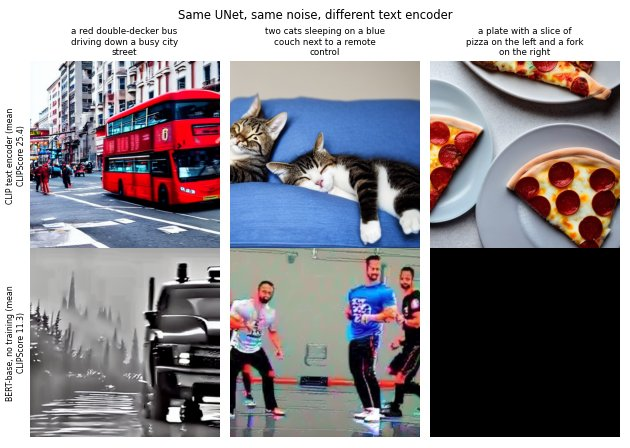

In [ ]:
from transformers import BertTokenizer, BertModel
btok = BertTokenizer.from_pretrained("bert-base-uncased")
bert = BertModel.from_pretrained("bert-base-uncased", dtype=DTYPE).to(DEVICE).eval()
with torch.no_grad():
    b_cond, b_uncond = [bert(**btok(t, padding="max_length", max_length=77, truncation=True,
                                    return_tensors="pt").to(DEVICE)).last_hidden_state
                        for t in (prompts[:3], [""])]
del bert; torch.cuda.empty_cache()
print("BERT embeddings:", tuple(b_cond.shape), "(same shape as CLIP, different space)")

enc_imgs, enc_scores = {}, {}
for name, c, u in [("CLIP", cond[:3], uncond), ("BERT", b_cond, b_uncond)]:
    imgs, dt, fl = generate(c, u, SEED, "DPM++ 2M Karras", 25, 7.5)
    enc_scores[name] = record(imgs, prompts[:3], SEED, SAMPLES_DIR / "encoder_clip_vs_bert", f"encoder: {name}",
                              "DPM++ 2M Karras", 25, 7.5, dt, fl, tag=f"{name.lower()}_")
    enc_imgs[name] = imgs

g = save_grid([enc_imgs["CLIP"], enc_imgs["BERT"]], PLOTS_DIR / "m2_encoder_clip_vs_bert.jpg",
              row_labels=[f"CLIP text encoder\n(mean CLIPScore {np.nanmean(enc_scores['CLIP']):.1f})",
                          f"BERT-base, no training\n(mean CLIPScore {np.nanmean(enc_scores['BERT']):.1f})"],
              col_labels=prompts[:3], title="Same UNet, same noise, different text encoder")
show(g, 900)

## 2. Baseline conditional generation
Baseline = SD defaults (PNDM, 50 steps, `w = 7.5`) on seeds 39–42, the same seeds used for the tuned config in Task-4. We also sample with an empty prompt from the same noise to show the text is doing the work.

Metric: **CLIPScore** = 100 × cosine similarity between image and prompt in CLIP space (higher = more faithful).

In [ ]:
BASE = dict(scheduler="PNDM (SD default)", steps=50, guidance=7.5)
EVAL_SEEDS = [SEED, SEED + 1, SEED + 2, SEED + 3]

for s in EVAL_SEEDS:
    imgs, dt, fl = generate(cond, uncond, s, **BASE)
    sc = record(imgs, prompts, s, SAMPLES_DIR / "baseline", "baseline (conditional)", **BASE, runtime_s=dt,
                flags=fl, ext="png" if s == SEED else "jpg", notes="M2 baseline = SD defaults")
    if s == SEED:
        base_imgs, base_scores, base_dt = imgs, sc, dt

unc_imgs, unc_dt, unc_fl = generate(uncond.expand(len(prompts), -1, -1), uncond, SEED, BASE["scheduler"], BASE["steps"], 1.0)
unc_scores = record(unc_imgs, prompts, SEED, SAMPLES_DIR / "baseline", "unconditional", BASE["scheduler"],
                    BASE["steps"], 1.0, unc_dt, unc_fl, tag="uncond_",
                    notes="empty prompt, no CFG; scored against the test prompt")

print(f"{base_dt:.1f}s / image")
pd.DataFrame({"prompt": prompts, "conditional": base_scores, "unconditional": unc_scores})

8.8s / image


,prompt,conditional,unconditional
0,a red double-decker bus driving down a busy ci...,26.30,10.76
1,two cats sleeping on a blue couch next to a re...,30.33,14.89
2,a plate with a slice of pizza on the left and ...,22.85,8.46
3,a man riding a surfboard on a large wave at su...,28.05,6.09
4,a bowl of oranges and bananas on a wooden kitc...,25.09,7.33


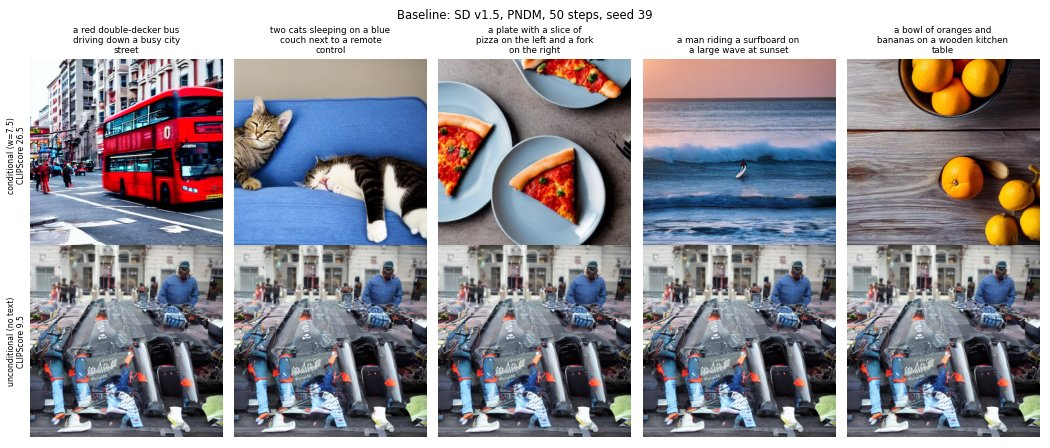

text conditioning adds +17.0 CLIPScore on average


In [ ]:
g = save_grid([base_imgs, unc_imgs], PLOTS_DIR / "m2_baseline_cond_vs_uncond.jpg",
              row_labels=[f"conditional (w=7.5)\nCLIPScore {np.nanmean(base_scores):.1f}",
                          f"unconditional (no text)\nCLIPScore {np.nanmean(unc_scores):.1f}"],
              col_labels=prompts, title="Baseline: SD v1.5, PNDM, 50 steps, seed 39")
show(g, 1100)
print(f"text conditioning adds {np.nanmean(base_scores) - np.nanmean(unc_scores):+.1f} CLIPScore on average")